# 02 · Cash-Flow Modeling
Project monthly cash flows for one tranche with prepayment (CPR → SMM), defaults (CDR → MDR) and loss severity, then price it and measure WAL and effective duration.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, '../scripts')
pd.set_option('display.width', 140)
portfolio = pd.read_csv('../data/sample_portfolio.csv', parse_dates=['maturity'])
from model import Assumptions, project_cashflows, price, wal, effective_duration, months_to

In [2]:
row = portfolio[portfolio['sector'] == 'RMBS'].iloc[0]
months = months_to(row.maturity, pd.Timestamp('2025-10-01'))
cf = project_cashflows(row.notional, row.coupon, months, Assumptions(row.cpr, row.cdr, row.severity))
print(row[['id', 'sector', 'tranche', 'rating', 'coupon', 'cpr', 'cdr', 'severity', 'spread_bps']].to_string())
cf.head()

id            TRN1006
sector           RMBS
tranche        Senior
rating            AAA
coupon         0.0597
cpr            0.0633
cdr             0.002
severity         0.35
spread_bps        136


,month,begin_balance,interest,scheduled_principal,prepayment,recovery,loss,total_cash
0,1,4.720000e+07,234780.827412,122216.215319,255802.874204,5118.026554,2755.860452,617917.943489
1,2,4.681411e+07,232861.330117,122136.370727,253706.510708,5076.183111,2733.329367,613780.394663
2,3,4.643045e+07,230952.977861,122056.578298,251622.321412,5034.582620,2710.929103,609666.460192
3,4,4.604903e+07,229055.707969,121976.837998,249550.237853,4993.223717,2688.658924,605576.007537
4,5,4.566982e+07,227169.458117,121897.149793,247490.191949,4952.105040,2666.518099,601508.904899


In [3]:
print(f"Price:              {price(cf, row.notional, row.spread_bps):.3f}")
print(f"WAL:                {wal(cf):.2f} years")
print(f"Effective duration: {effective_duration(cf, row.notional, row.spread_bps):.2f}")
print(f"Cumulative loss:    {100 * cf['loss'].sum() / row.notional:.2f}% of original balance")

Price:              101.570
WAL:                7.17 years
Effective duration: 5.42
Cumulative loss:    0.50% of original balance


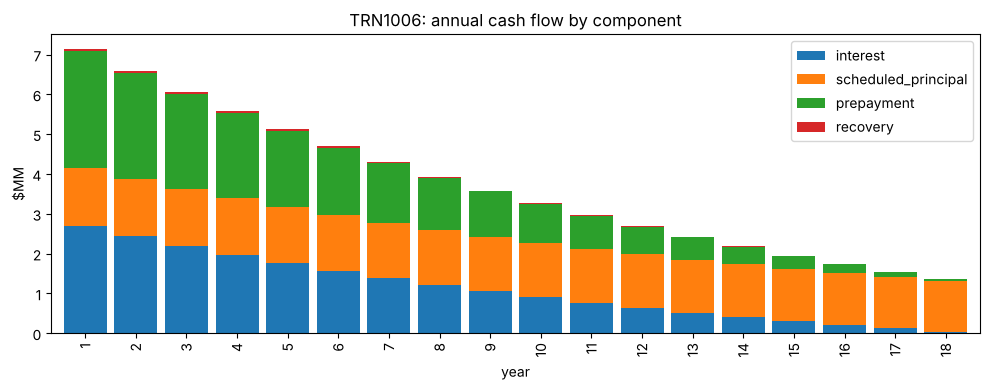

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
yearly = cf.assign(year=(cf['month'] - 1) // 12 + 1).groupby('year')[['interest', 'scheduled_principal', 'prepayment', 'recovery']].sum() / 1e6
yearly.plot.bar(stacked=True, ax=ax, width=0.85)
ax.set_ylabel('$MM'); ax.set_title(f'{row.id}: annual cash flow by component'); plt.tight_layout()

## Prepayment sensitivity
Faster prepayments return principal sooner, shortening WAL. For a bond priced below par that early return at par adds value.

In [5]:
rows = []
for cpr in [0.02, 0.05, 0.10, 0.15, 0.25]:
    c = project_cashflows(row.notional, row.coupon, months, Assumptions(cpr, row.cdr, row.severity))
    rows.append({'CPR': cpr, 'price': price(c, row.notional, row.spread_bps), 'WAL (yrs)': wal(c)})
pd.DataFrame(rows).round(3)

,CPR,price,WAL (yrs)
0,0.02,101.947,9.262
1,0.05,101.674,7.734
2,0.10,101.328,5.875
3,0.15,101.079,4.598
4,0.25,100.754,3.037
